# 04 · Placar das três configurações e os cinco erros

**Critérios da rubrica:** 06 (placar das três configurações, com resultados interpretados) e 07 (cinco erros reais com proposta de correção).

Este notebook lê os resultados gravados por `python scripts/avaliar.py` (um arquivo por configuração em `avaliacao/resultados/`, com a resposta completa e a correção de cada caso). Para refazer a medição do zero, rode o script e execute o notebook de novo.

**Definições.** *Acerto*: em caso respondível, respondeu e a resposta contém os fatos do gabarito; em caso "não consta", recusou. *Alucinação*: respondeu o que não consta, afirmou um fato sabidamente errado, citou fonte que não existe ou apresentou dado de loja que não confere. A correção é automática (`src/consultor/avaliacao.py`) e cada resposta fica gravada para conferência manual.

In [1]:
import sys, json
from pathlib import Path
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
import pandas as pd
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 220)
from consultor import config
print("modelo:", config.MODELO_LLM, "| embeddings:", config.MODELO_EMBEDDING, "| limiar de recusa:", config.limiar_recusa())

modelo: qwen2.5:7b | embeddings: bge-m3 | limiar de recusa: 0.56


In [2]:
from consultor import avaliacao
import matplotlib.pyplot as plt
NOMES = {"puro": "1. Modelo puro", "rag": "2. RAG simples", "agente": "3. Agente"}
def carregar(config_nome):
    return [json.loads(l) for l in open(RAIZ / "avaliacao" / "resultados" / f"teste_{config_nome}.jsonl", encoding="utf-8")]
resultados = {nome: carregar(nome) for nome in NOMES}
placar = pd.DataFrame({NOMES[n]: avaliacao.resumir([r["correcao"] for r in rs]) for n, rs in resultados.items()}).T
print("casos de teste:", int(placar["casos"].iloc[0]))
display(placar[["acerto_%", "alucinacao_%", "alucinacao_automatica_%", "acerto_respondiveis_%", "recusa_correta_%", "recusa_indevida_%", "citacao_correta_%", "json_valido_%", "segundos_medio"]])
print("alucinacao_% inclui a revisão manual de todas as respostas (avaliacao/revisao_manual.json); alucinacao_automatica_% é só a correção por regras.")

casos de teste: 44


,acerto_%,alucinacao_%,alucinacao_automatica_%,acerto_respondiveis_%,recusa_correta_%,recusa_indevida_%,citacao_correta_%,json_valido_%,segundos_medio
1. Modelo puro,31.8,40.9,9.1,15.6,75.0,25.0,0.0,100.0,2.74
2. RAG simples,72.7,2.3,0.0,62.5,100.0,34.4,100.0,100.0,2.21
3. Agente,90.9,4.5,0.0,87.5,100.0,6.2,100.0,100.0,8.41


alucinacao_% inclui a revisão manual de todas as respostas (avaliacao/revisao_manual.json); alucinacao_automatica_% é só a correção por regras.


### Revisão manual

A correção automática compara palavras do gabarito. Ela não percebe um prazo ou um valor inventado que ninguém previu no gabarito. Por isso as 132 respostas do teste foram lidas, e os casos em que a resposta afirma algo que contradiz o gabarito foram registrados, com justificativa, em `avaliacao/revisao_manual.json`. O critério é o mesmo para as três configurações.

In [3]:
revisao = json.loads((RAIZ / "avaliacao" / "revisao_manual.json").read_text(encoding="utf-8"))
linhas = [{"config": c, "caso": k, "muda": "acerto" if "acerto" in v else "alucinação", "nota": v["nota"]} for c in ("puro", "rag", "agente") for k, v in revisao[c].items()]
display(pd.DataFrame(linhas))

,config,caso,muda,nota
0,puro,t03,alucinação,Afirma que as bandeiras existem desde 2010; o correto é 2015.
1,puro,t05,alucinação,Conclui que vale a pena migrar; o exemplo da ANEEL para esse perfil diz que não há vantagem significativa.
2,puro,t06,alucinação,Diz que a ponta vai das 7h às 22h; a ponta dura 3 horas consecutivas.
3,puro,t07,alucinação,Inventa o prazo '28º dia útil'; o correto é 180 dias.
4,puro,t08,alucinação,Inventa '48 horas' e '10 dias úteis'; o correto é até 30 dias.
5,puro,t09,alucinação,Diz que não há distinção nos fins de semana; o correto é tarifa fora de ponta.
6,puro,t10,alucinação,Afirma 10 ºC; a RDC 216 exige temperatura inferior a 5 ºC.
7,puro,t11,alucinação,Afirma 3 dias; a RDC 216 fixa no máximo 5 dias a 4 ºC.
8,puro,t13,acerto,"A correção automática aceitou por causa da palavra 'fechar' em 'quando a loja fechar'. A resposta manda desligar os balcões, o que a base só admite quando o..."
9,puro,t15,alucinação,Recomenda 24 a 26 ºC; a fonte recomenda 22 a 24 ºC.


In [4]:
display(placar[["acerto_factual_%", "acerto_calculo_%", "acerto_loja_%", "acerto_nao_consta_%"]])
contagem = pd.Series({c: sum(1 for r in resultados["rag"] if r["correcao"]["categoria"] == c) for c in avaliacao.CATEGORIAS}, name="casos por categoria")
print(contagem.to_string())

,acerto_factual_%,acerto_calculo_%,acerto_loja_%,acerto_nao_consta_%
1. Modelo puro,25.0,0.0,0.0,75.0
2. RAG simples,90.0,33.3,0.0,100.0
3. Agente,95.0,66.7,83.3,100.0


factual       20
calculo        6
loja           6
nao_consta    12


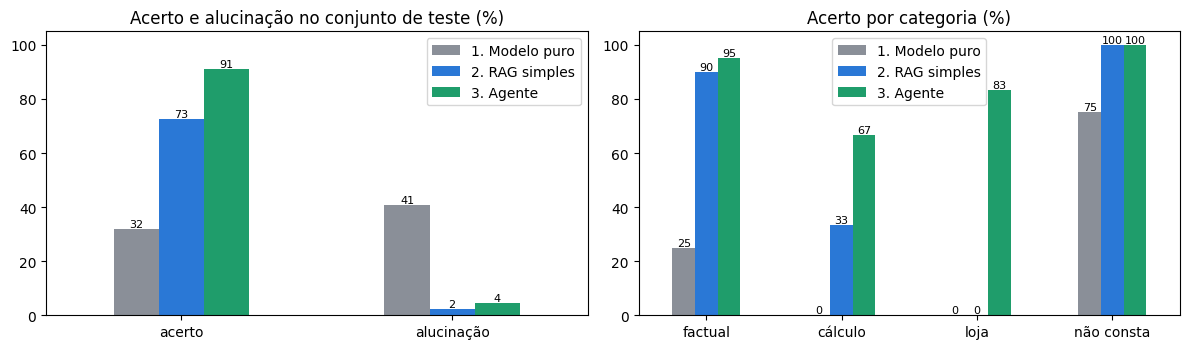

In [5]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.6))
cores = ["#8a8f98", "#2a78d6", "#1f9d6b"]
placar[["acerto_%", "alucinacao_%"]].rename(columns={"acerto_%": "acerto", "alucinacao_%": "alucinação"}).T.plot.bar(ax=eixos[0], color=cores, rot=0)
eixos[0].set_title("Acerto e alucinação no conjunto de teste (%)"); eixos[0].set_ylim(0, 105)
for barra in eixos[0].containers:
    eixos[0].bar_label(barra, fmt="%.0f", fontsize=8)
porcat = placar[["acerto_factual_%", "acerto_calculo_%", "acerto_loja_%", "acerto_nao_consta_%"]]
porcat.columns = ["factual", "cálculo", "loja", "não consta"]
porcat.T.plot.bar(ax=eixos[1], color=cores, rot=0)
eixos[1].set_title("Acerto por categoria (%)"); eixos[1].set_ylim(0, 105)
for barra in eixos[1].containers:
    eixos[1].bar_label(barra, fmt="%.0f", fontsize=8)
plt.tight_layout(); plt.savefig(RAIZ / "avaliacao" / "placar.png", dpi=130); plt.show()

## Como cada resposta foi decidida

In [6]:
decisoes = pd.DataFrame({NOMES[n]: pd.Series([r["resposta"]["motivo"] for r in rs]).value_counts() for n, rs in resultados.items()}).fillna(0).astype(int)
display(decisoes)
aluc = pd.DataFrame({NOMES[n]: pd.Series([m for r in rs for m in r["correcao"]["motivos_alucinacao"]]).value_counts() for n, rs in resultados.items()}).fillna(0).astype(int)
print("tipos de alucinação por configuração:"); display(aluc)

,1. Modelo puro,2. RAG simples,3. Agente
recusa_limiar,0,20,0
recusa_modelo,17,3,2
recusa_sem_evidencia,0,0,12
resposta,0,21,30
resposta_sem_verificacao,27,0,0


tipos de alucinação por configuração:


,1. Modelo puro,2. RAG simples,3. Agente
dado de loja não confere,1,0,0
fato errado (revisão manual),14,1,2
respondeu o que não consta,3,0,0


## Demonstração de alucinações do modelo puro

Respostas reais do modelo sem contexto a casos do conjunto de teste.

In [7]:
for r in resultados["puro"]:
    if r["correcao"]["alucinacao"]:
        s = r["resposta"]["saida"]
        print(f"[{r['caso']}] {r['pergunta']}")
        print("   gabarito :", r["gabarito"])
        print("   resposta :", s["recomendacao"][:300])
        print("   fonte    :", s["fonte"], "| motivo:", r["correcao"]["motivos_alucinacao"]); print()

[t03] Desde que ano existe o sistema de bandeiras tarifárias?
   gabarito : Desde 2015.
   resposta : O sistema de bandeiras tarifárias no Brasil existe desde 2010.
   fonte    : None | motivo: ['fato errado (revisão manual)']

[t05] Minha padaria funciona das 8h às 20h de segunda a sábado e fecha no domingo. Vale a pena migrar para a tarifa branca?
   gabarito : Pelo exemplo da ANEEL para esse perfil, não há vantagem significativa: as contas ficam quase iguais.
   resposta : Sim, vale a pena migrar para a tarifa branca, pois você opera durante o horário comercial, podendo aproveitar as tarifas mais baixas durante o dia.
   fonte    : None | motivo: ['fato errado (revisão manual)']

[t06] Quanto tempo dura o horário de ponta da tarifa?
   gabarito : Três horas consecutivas por dia, exceto sábados, domingos e feriados nacionais.
   resposta : O horário de ponta da tarifa varia conforme a região, mas geralmente ocorre entre 7h e 22h de segunda a sexta-feira. Durante este período, os cust

## Todos os erros do RAG simples e do agente

In [8]:
linhas = []
for nome in ("rag", "agente"):
    for r in resultados[nome]:
        if not r["correcao"]["acerto"]:
            linhas.append({"config": nome, "caso": r["caso"], "categoria": r["correcao"]["categoria"], "decisão": r["resposta"]["motivo"],
                           "alucinação": r["correcao"]["alucinacao"], "pergunta": r["pergunta"], "resposta": r["resposta"]["saida"]["recomendacao"][:150]})
display(pd.DataFrame(linhas))

,config,caso,categoria,decisão,alucinação,pergunta,resposta
0,rag,t16,factual,recusa_limiar,False,Como evitar que a luz do estoque fique acesa sem ninguém lá dentro?,
1,rag,t19,factual,recusa_modelo,False,Como um comércio pode apresentar um projeto ao Programa de Eficiência Energética da ANEEL?,
2,rag,t21,calculo,recusa_limiar,False,"Um expositor ficou com a porta aberta por 2 horas no total durante o mês. Usando os valores padrão do produto, quanto isso custou?",
3,rag,t24,calculo,recusa_limiar,False,"Somando o mês todo, os expositores ficaram 40 horas com a porta aberta. Qual é o desperdício estimado em reais com os valores padrão do produto?",
4,rag,t25,calculo,recusa_modelo,False,"Qual é o custo estimado de 10 horas de porta aberta em um freezer se a tarifa for R$ 1,10 por kWh e os demais valores forem os padrão do produto?",
5,rag,t26,calculo,resposta,True,"Quantos kWh são desperdiçados em 6 horas de porta aberta em um expositor, pelos valores padrão do produto?","Com base nos valores padrão (potencia_kw = 0,50 e fator_perda = 0,30), 6 horas de porta aberta resultam em 0,09 kWh de energia desperdiçada."
6,rag,t27,loja,recusa_limiar,False,Qual equipamento da padaria-01 mais desperdiçou energia em 2026-10 e o que devo fazer?,
7,rag,t28,loja,recusa_limiar,False,Qual foi o maior desperdício do mercado-01 em 2026-10 e qual é a recomendação?,
8,rag,t29,loja,recusa_limiar,False,Quanto a padaria-01 desperdiçou em reais em 2026-10?,
9,rag,t30,loja,recusa_limiar,False,Quantos kWh o mercado-01 desperdiçou em 2026-10?,


## Os cinco erros analisados

Selecionados em `avaliacao/erros_selecionados.json`. Cada um mostra a saída real gravada, a causa e a correção proposta.

In [9]:
erros = json.loads((RAIZ / "avaliacao" / "erros_selecionados.json").read_text(encoding="utf-8"))
for i, e in enumerate(erros, 1):
    r = next(x for x in resultados[e["config"]] if x["caso"] == e["caso"])
    resp = r["resposta"]
    print(f"ERRO {i} · {e['titulo']}")
    print(f"  configuração : {NOMES[e['config']]}   caso: {e['caso']} ({r['correcao']['categoria']})")
    print(f"  pergunta     : {r['pergunta']}")
    print(f"  gabarito     : {r['gabarito']}")
    print(f"  saída real   : {json.dumps(resp['saida'], ensure_ascii=False)}")
    print(f"  decisão      : {resp['motivo']} | melhor similaridade: {resp['score_top1']} | limiar: {resp['limiar']}")
    if resp["trechos"]:
        print(f"  trechos      : {resp['trechos']}")
    for p in resp["passos"]:
        if not p.get("automatico"):
            print(f"  ferramenta   : {p['ferramenta']}({json.dumps(p['argumentos'], ensure_ascii=False)})")
    print(f"  causa        : {e['causa']}")
    print(f"  correção     : {e['correcao']}")
    print()

ERRO 1 · O limiar de recusa barrou uma pergunta que a base responde
  configuração : 2. RAG simples   caso: t16 (factual)
  pergunta     : Como evitar que a luz do estoque fique acesa sem ninguém lá dentro?
  gabarito     : Usar sensores de presença e desligar as luzes das dependências que não estão em uso.
  saída real   : {"nao_consta": true, "recomendacao": "", "fonte": null}
  decisão      : recusa_limiar | melhor similaridade: 0.549 | limiar: 0.56
  trechos      : [['ana-dicas-02', 0.549], ['procel-refrigeracao-07', 0.5154], ['ana-a3p-01', 0.4998]]
  causa        : A busca achou o trecho certo em primeiro lugar (ana-dicas-02, sensores de presença), mas com similaridade 0,549, abaixo do limiar de 0,56. O limiar foi calibrado com 19 perguntas respondíveis; a pergunta do teste usa uma redação coloquial ('luz do estoque acesa sem ninguém lá dentro') mais distante do texto da fonte do que qualquer pergunta da calibração. O sistema recusou sem nem chamar a LLM. O mesmo aconteceu nos cas